# Visualizing a 2D multivariate Gaussian

Consider

$$
\mathbf X=
\begin{pmatrix}
X\\Y
\end{pmatrix}
\sim
\mathcal N(\boldsymbol\mu,\Sigma),
$$

with

$$
\boldsymbol\mu=
\begin{pmatrix}
\mu_X\\
\mu_Y
\end{pmatrix},
\qquad
\Sigma=
\begin{pmatrix}
\sigma_X^2 & \sigma_{XY}\\
\sigma_{XY} & \sigma_Y^2
\end{pmatrix}.
$$

The goal of this notebook is to make every part of \(\Sigma\) visually interpretable.

$$
\boxed{
\Sigma_{11}=\operatorname{Var}(X)
\;\Rightarrow\;
\text{horizontal spread}
}
$$

$$
\boxed{
\Sigma_{22}=\operatorname{Var}(Y)
\;\Rightarrow\;
\text{vertical spread}
}
$$

$$
\boxed{
\Sigma_{12}=\Sigma_{21}=\operatorname{Cov}(X,Y)
\;\Rightarrow\;
\text{tilt / orientation}
}
$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

rng = np.random.default_rng(4)
plt.rcParams["figure.figsize"] = (7, 5)

## 1. Start with an isotropic Gaussian

Let

$$
\boldsymbol\mu=
\begin{pmatrix}
0\\0
\end{pmatrix},
\qquad
\Sigma=
\begin{pmatrix}
1&0\\
0&1
\end{pmatrix}.
$$

Both variables have the same variance, and the covariance is zero.

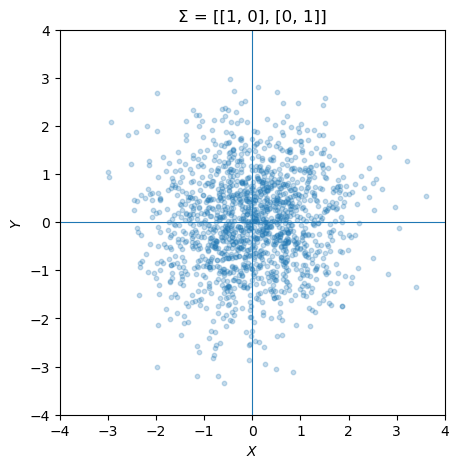

In [5]:
mu = np.array([0.0, 0.0])
Sigma = np.array([
    [1.0, 0.0],
    [0.0, 1.0]
])

samples = rng.multivariate_normal(mu, Sigma, size=1500)

plt.scatter(samples[:, 0], samples[:, 1], alpha=0.25, s=10)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlim(-4, 4)
plt.ylim(-4, 4)
plt.gca().set_aspect("equal")
plt.xlabel("$X$")
plt.ylabel("$Y$")
#plt.title(r"$\Sigma=\begin{pmatrix}1&0\\0&1\end{pmatrix}$")
plt.title("Σ = [[1, 0], [0, 1]]")
plt.show()

### Interpretation

The cloud is approximately circular because

$$
\operatorname{Var}(X)=\operatorname{Var}(Y)=1
$$

and

$$
\operatorname{Cov}(X,Y)=0.
$$

There is no preferred direction.

## 2. Change only \(\Sigma_{11}\)

Now increase only the variance of \(X\):

$$
\Sigma=
\begin{pmatrix}
4&0\\
0&1
\end{pmatrix}.
$$

The standard deviation of \(X\) changes from \(1\) to \(2\), while \(Y\) is unchanged.

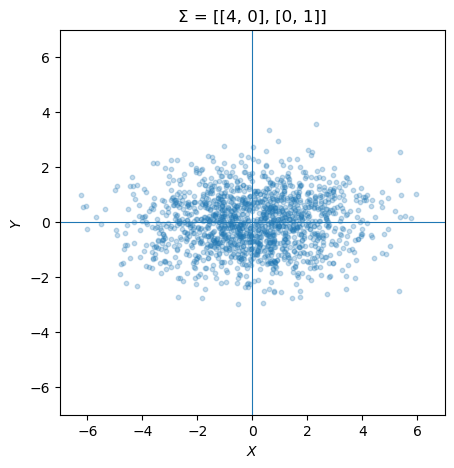

In [7]:
Sigma = np.array([
    [4.0, 0.0],
    [0.0, 1.0]
])

samples = rng.multivariate_normal(mu, Sigma, size=1500)

plt.scatter(samples[:, 0], samples[:, 1], alpha=0.25, s=10)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlim(-7, 7)
plt.ylim(-7, 7)
plt.gca().set_aspect("equal")
plt.xlabel("$X$")
plt.ylabel("$Y$")
#plt.title(r"$\Sigma=\begin{pmatrix}4&0\\0&1\end{pmatrix}$")
plt.title("Σ = [[4, 0], [0, 1]]")
plt.show()

$$
\boxed{
\Sigma_{11}\text{ controls spread along the }X\text{-direction.}
}
$$

## 3. Change only \(\Sigma_{22}\)

Now instead use

$$
\Sigma=
\begin{pmatrix}
1&0\\
0&4
\end{pmatrix}.
$$

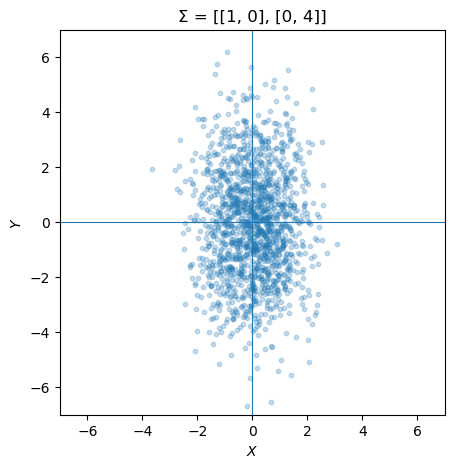

In [9]:
Sigma = np.array([
    [1.0, 0.0],
    [0.0, 4.0]
])

samples = rng.multivariate_normal(mu, Sigma, size=1500)

plt.scatter(samples[:, 0], samples[:, 1], alpha=0.25, s=10)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlim(-7, 7)
plt.ylim(-7, 7)
plt.gca().set_aspect("equal")
plt.xlabel("$X$")
plt.ylabel("$Y$")
#plt.title(r"$\Sigma=\begin{pmatrix}1&0\\0&4\end{pmatrix}$")
plt.title("Σ = [[1, 0], [0, 4]]")
plt.show()

$$
\boxed{
\Sigma_{22}\text{ controls spread along the }Y\text{-direction.}
}
$$

## 4. Positive covariance

Keep the marginal variances fixed but introduce positive covariance:

$$
\Sigma=
\begin{pmatrix}
2&1.5\\
1.5&2
\end{pmatrix}.
$$

Now large values of \(X\) tend to occur with large values of \(Y\), and small values of \(X\) tend to occur with small values of \(Y\).

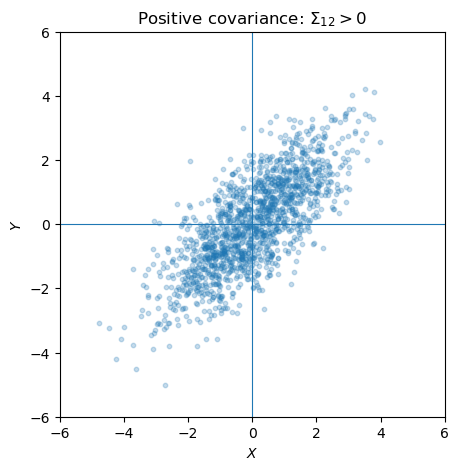

In [10]:
Sigma = np.array([
    [2.0, 1.5],
    [1.5, 2.0]
])

samples = rng.multivariate_normal(mu, Sigma, size=1500)

plt.scatter(samples[:, 0], samples[:, 1], alpha=0.25, s=10)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlim(-6, 6)
plt.ylim(-6, 6)
plt.gca().set_aspect("equal")
plt.xlabel("$X$")
plt.ylabel("$Y$")
plt.title(r"Positive covariance: $\Sigma_{12}>0$")
plt.show()

\[
\boxed{
\operatorname{Cov}(X,Y)>0
\quad\Rightarrow\quad
\text{the cloud tilts upward.}
}
\]

## 5. Negative covariance

Now use

$$
\Sigma=
\begin{pmatrix}
2&-1.5\\
-1.5&2
\end{pmatrix}.
$$

Large values of \(X\) now tend to occur with small values of \(Y\).

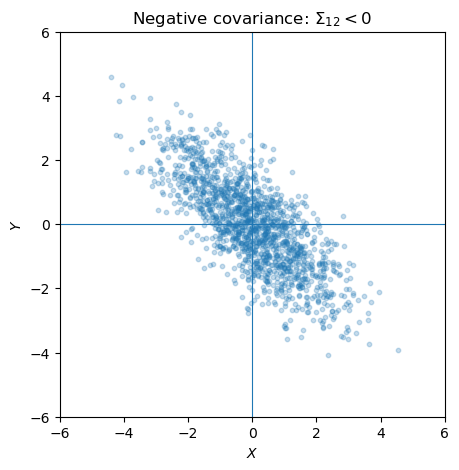

In [11]:
Sigma = np.array([
    [2.0, -1.5],
    [-1.5, 2.0]
])

samples = rng.multivariate_normal(mu, Sigma, size=1500)

plt.scatter(samples[:, 0], samples[:, 1], alpha=0.25, s=10)
plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)
plt.xlim(-6, 6)
plt.ylim(-6, 6)
plt.gca().set_aspect("equal")
plt.xlabel("$X$")
plt.ylabel("$Y$")
plt.title(r"Negative covariance: $\Sigma_{12}<0$")
plt.show()

$$
\boxed{
\operatorname{Cov}(X,Y)<0
\quad\Rightarrow\quad
\text{the cloud tilts downward.}
}
$$

## 6. Compare several covariance matrices side by side

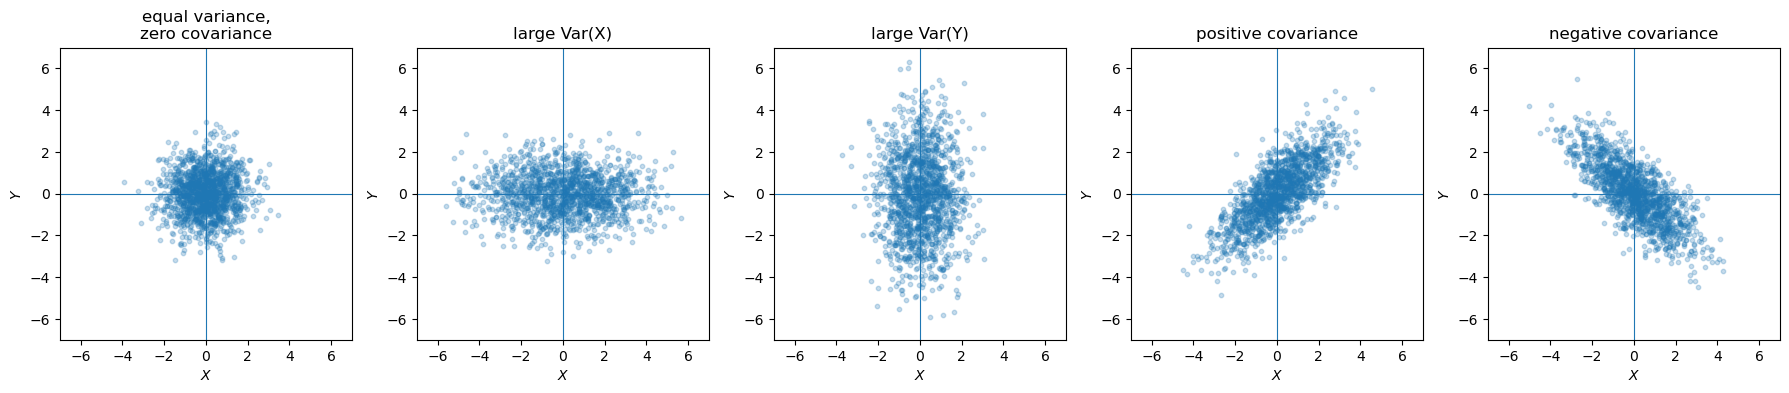

In [12]:
covariances = [
    np.array([[1.0, 0.0],
              [0.0, 1.0]]),

    np.array([[4.0, 0.0],
              [0.0, 1.0]]),

    np.array([[1.0, 0.0],
              [0.0, 4.0]]),

    np.array([[2.0, 1.5],
              [1.5, 2.0]]),

    np.array([[2.0, -1.5],
              [-1.5, 2.0]])
]

titles = [
    "equal variance,\nzero covariance",
    "large Var(X)",
    "large Var(Y)",
    "positive covariance",
    "negative covariance"
]

fig, axes = plt.subplots(1, 5, figsize=(18, 3.8))

for ax, Sigma, title in zip(axes, covariances, titles):
    samples = rng.multivariate_normal(mu, Sigma, size=1500)

    ax.scatter(samples[:, 0], samples[:, 1], alpha=0.25, s=10)
    ax.axhline(0, linewidth=0.8)
    ax.axvline(0, linewidth=0.8)
    ax.set_xlim(-7, 7)
    ax.set_ylim(-7, 7)
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.set_xlabel("$X$")
    ax.set_ylabel("$Y$")

plt.tight_layout()
plt.show()

## 7. Covariance versus correlation

Covariance depends on the units of \(X\) and \(Y\).

A dimensionless measure is the correlation coefficient

$$
\rho
=
\frac{\operatorname{Cov}(X,Y)}
{\sigma_X\sigma_Y}.
$$

It always satisfies

$$
-1\le \rho\le1.
$$

If

$$
\operatorname{Var}(X)=\operatorname{Var}(Y)=1,
$$

then

$$
\Sigma=
\begin{pmatrix}
1&\rho\\
\rho&1
\end{pmatrix}.
$$

So in this special case the off-diagonal entry is directly the correlation.

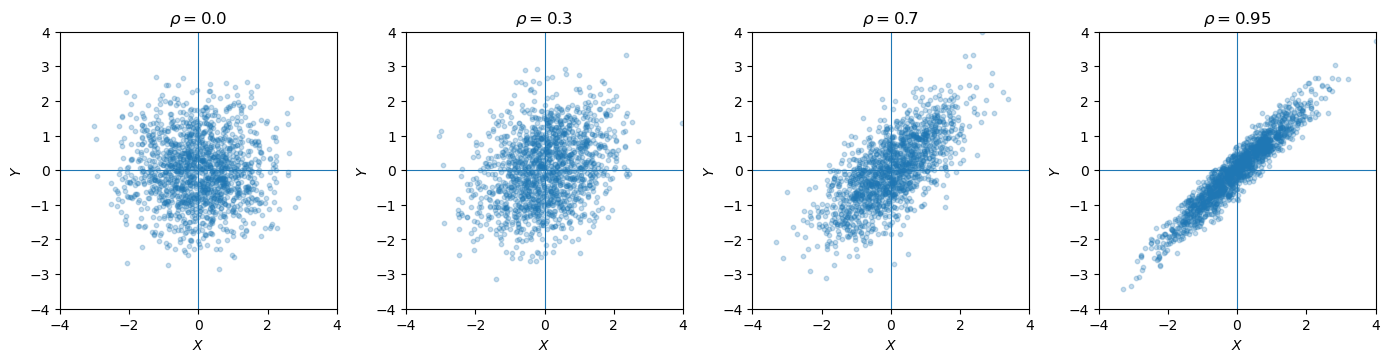

In [13]:
rhos = [0.0, 0.3, 0.7, 0.95]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))

for ax, rho in zip(axes, rhos):

    Sigma = np.array([
        [1.0, rho],
        [rho, 1.0]
    ])

    samples = rng.multivariate_normal(mu, Sigma, size=1500)

    ax.scatter(samples[:, 0], samples[:, 1], alpha=0.25, s=10)
    ax.axhline(0, linewidth=0.8)
    ax.axvline(0, linewidth=0.8)
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect("equal")
    ax.set_title(rf"$\rho={rho}$")
    ax.set_xlabel("$X$")
    ax.set_ylabel("$Y$")

plt.tight_layout()
plt.show()

As \(\rho\) increases:

$$
\rho=0
$$

gives almost no preferred orientation,

while

$$
\rho\to1
$$

makes the cloud increasingly concentrated around a line.

## 8. Covariance ellipses

The scatter cloud can be summarized geometrically by an ellipse.

For a Gaussian distribution,

$$
\Sigma
$$

determines:

- the orientation of the ellipse,
- the lengths of its principal axes.

The eigenvectors of \(\Sigma\) determine the directions,
and the square roots of the eigenvalues determine the scale along those directions.

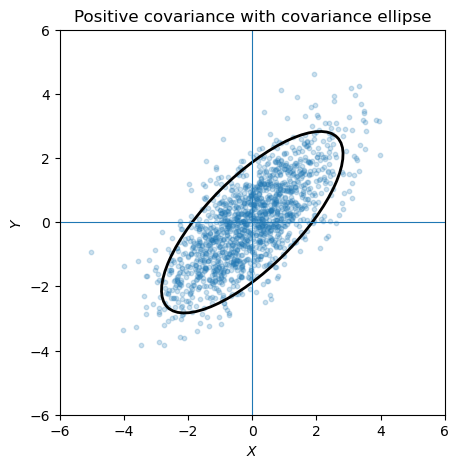

In [14]:
def plot_gaussian_with_ellipse(Sigma, title, n=1500):
    samples = rng.multivariate_normal(mu, Sigma, size=n)

    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(samples[:, 0], samples[:, 1], alpha=0.22, s=10)

    eigvals, eigvecs = np.linalg.eigh(Sigma)
    order = np.argsort(eigvals)[::-1]
    eigvals = eigvals[order]
    eigvecs = eigvecs[:, order]

    angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))

    # 2 standard-deviation ellipse
    width = 2 * 2 * np.sqrt(eigvals[0])
    height = 2 * 2 * np.sqrt(eigvals[1])

    ellipse = Ellipse(
        xy=mu,
        width=width,
        height=height,
        angle=angle,
        fill=False,
        linewidth=2
    )

    ax.add_patch(ellipse)

    ax.axhline(0, linewidth=0.8)
    ax.axvline(0, linewidth=0.8)
    ax.set_aspect("equal")
    ax.set_xlabel("$X$")
    ax.set_ylabel("$Y$")
    ax.set_title(title)

    lim = 6
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

    plt.show()


plot_gaussian_with_ellipse(
    np.array([[2.0, 1.5],
              [1.5, 2.0]]),
    "Positive covariance with covariance ellipse"
)

### Why eigenvectors and eigenvalues?

For

$$
\Sigma v=\lambda v,
$$

the eigenvector \(v\) gives a direction in which the covariance matrix acts without rotating the vector.

For a Gaussian cloud:

$$
\boxed{
\text{eigenvectors}
\;\Rightarrow\;
\text{principal directions}
}
$$

and

$$
\boxed{
\sqrt{\lambda}
\;\Rightarrow\;
\text{standard deviation along that direction}.
}
$$

## 9. Move the mean without changing the covariance

The mean vector controls the **location** of the cloud.

The covariance matrix controls its **shape and orientation**.

Compare

$$
\boldsymbol\mu=
\begin{pmatrix}
0\\0
\end{pmatrix}
$$

with

$$
\boldsymbol\mu=
\begin{pmatrix}
3\\2
\end{pmatrix}
$$

while keeping exactly the same covariance matrix.

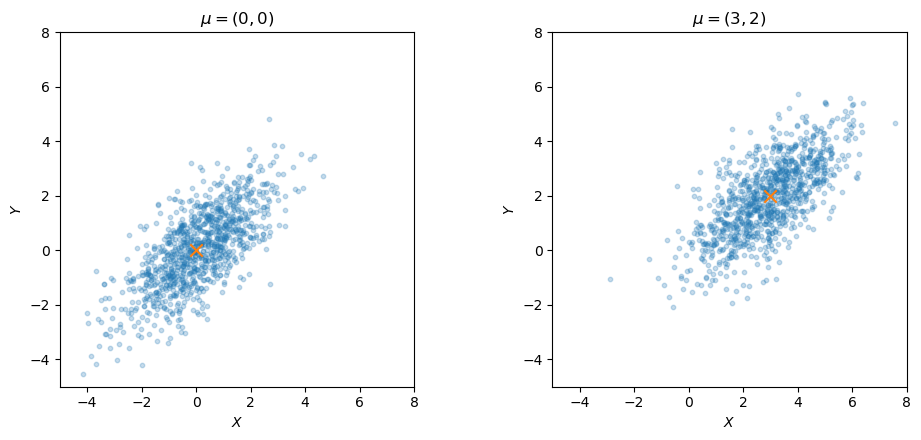

In [15]:
Sigma = np.array([
    [2.0, 1.4],
    [1.4, 2.0]
])

mu1 = np.array([0.0, 0.0])
mu2 = np.array([3.0, 2.0])

s1 = rng.multivariate_normal(mu1, Sigma, size=1000)
s2 = rng.multivariate_normal(mu2, Sigma, size=1000)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

for ax, samples, m, title in [
    (axes[0], s1, mu1, r"$\mu=(0,0)$"),
    (axes[1], s2, mu2, r"$\mu=(3,2)$")
]:
    ax.scatter(samples[:, 0], samples[:, 1], alpha=0.25, s=10)
    ax.scatter(m[0], m[1], s=80, marker="x")
    ax.set_xlim(-5, 8)
    ax.set_ylim(-5, 8)
    ax.set_aspect("equal")
    ax.set_xlabel("$X$")
    ax.set_ylabel("$Y$")
    ax.set_title(title)

plt.tight_layout()
plt.show()

The shape is unchanged because \(\Sigma\) is unchanged.

Only the center moves.

$$
\boxed{
\boldsymbol\mu
\;\Rightarrow\;
\text{where the cloud is centered}
}
$$

$$
\boxed{
\Sigma
\;\Rightarrow\;
\text{spread, anisotropy, and orientation}
}
$$

# Summary

For

$$
\mathbf X=
\begin{pmatrix}
X\\Y
\end{pmatrix}
\sim
\mathcal N(\boldsymbol\mu,\Sigma),
$$

with

$$
\Sigma=
\begin{pmatrix}
\sigma_X^2 & \sigma_{XY}\\
\sigma_{XY} & \sigma_Y^2
\end{pmatrix},
$$

you can read the matrix geometrically:

$$
\boxed{
\sigma_X^2
\;\Rightarrow\;
\text{horizontal variability}
}
$$

$$
\boxed{
\sigma_Y^2
\;\Rightarrow\;
\text{vertical variability}
}
$$

$$
\boxed{
\sigma_{XY}
\;\Rightarrow\;
\text{direction and strength of linear co-variation}
}
$$

and

$$
\boxed{
\boldsymbol\mu
\;\Rightarrow\;
\text{location of the cloud}.
}
$$

This is the geometric meaning of the mean vector and covariance matrix.